# Heart Disease Risk Prediction
## DATASET AUDIT AND EXPLORATORY DATA ANALYSIS

This Notebook will helps us identify missing values, duplicate records, unusual values, class imbalance, and other data-quality concerns.
### OBJECTIVES
- Load and understand the raw dataset.
- Audit data quality: missing values, duplicates, data types, and value ranges.
- Explore individual features and relationships between features.
- Identify potential outliers without automatically deleting valid observations.
- Prepare and save a consistent dataset for the modelling stage.

**Dataset:** UCI Heart Disease Dataset (Cleveland subset)

### 1. Import libraries and configure the project

In [4]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

# Find the project directory by locating the raw data folder.
CURRENT_PATH = Path.cwd()
PROJECT_ROOT = next(
    (
        path for path in [CURRENT_PATH, *CURRENT_PATH.parents]
        if (path / "data" / "raw" / "processed.cleveland.data").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/processed.cleveland.data. "
        "Run this notebook from inside the project, or update the data path."
    )

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "processed.cleveland.data"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw dataset:", RAW_DATA_PATH)

Project root: C:\Users\ASUS\OneDrive\Documents\GitHub\heart-disease-risk-prediction
Raw dataset: C:\Users\ASUS\OneDrive\Documents\GitHub\heart-disease-risk-prediction\data\raw\processed.cleveland.data


### 2. Load the raw dataset

In [3]:
df = pd.read_csv(
    RAW_DATA_PATH,
    header=None,
    na_values="?"
)

print("Raw dataset loaded successfully.")
print(f"Number of records: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
display(df.head())

Raw dataset loaded successfully.
Number of records: 303
Number of columns: 14


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### 3. Assign meaningful column names
Original dataset doesn't include columns. We assign names based on the Cleveland heart-disease dataset structure.
### 3.1 Understand the Columns: Data Dictionary

| **Column** | **Meaning** | **Type / Unit** |
|:---|:---|:---|
| age | Patient age | Numeric, years |
| sex | Sex code (Female = 0, Male = 1) | Categorical |
| cp | Chest-pain type (Typical angina = 1, Atypical angina = 2, Non-anginal pain = 3, Asymptomatic = 4) | Categorical |
| trestbps | Resting blood pressure | Numeric, mm Hg |
| chol | Serum cholesterol | Numeric, mg/dL |
| fbs | Fasting blood sugar above 120 mg/dL (No = 0, Yes = 1) | Binary |
| restecg | Resting ECG (Normal = 0, ST-T wave abnormality = 1, Probable/definite left ventricular hypertrophy = 2) | Categorical |
| thalach | Maximum heart rate achieved | Numeric, beats/min |
| exang | Exercise-induced angina (No = 0, Yes = 1) | Binary |
| oldpeak | ST depression induced by exercise relative to rest | Numeric |
| slope | Peak exercise ST slope (Upsloping = 1, Flat = 2, Downsloping = 3) | Categorical |
| ca | Number of major vessels coloured by fluoroscopy | Count |
| thal | Thalassemia test code (Normal = 3, Fixed defect = 6, Reversible defect = 7) | Categorical |
| num | Original diagnosis severity (0–4) | Target source field |

In [4]:
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

if df.shape[1] != len(columns):
    raise ValueError(
        f"Expected {len(columns)} columns, but found {df.shape[1]}. "
        "Check that the correct raw dataset was loaded."
    )

df.columns = columns

display(df.head())


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### 4. Create the prediction target
The original num column represents the diagnosis result:
- 0: no heart disease indicated.
- Values greater than 0: some degree of heart disease indicated.
For this binary classification project, we convert it into a new column called target:
- target = 0: no heart disease.
- target = 1: heart disease present.

We retain num for audit and explanation, but exclude it from the model features. This prevents the original diagnosis field from leaking the answer into the model.

In [5]:
if df["num"].isna().any():
    raise ValueError(
        "The original diagnosis column (num) contains missing values. "
        "Resolve these records before creating the target."
    )

df["target"] = (df["num"] > 0).astype(int)

target_summary = (
    df["target"]
    .value_counts()
    .sort_index()
    .rename(index={0: "No heart disease", 1: "Heart disease"})
    .to_frame("Number of records")
)
target_summary["Percentage"] = (
    target_summary["Number of records"] / len(df) * 100
)

display(target_summary.round(2))

,Number of records,Percentage
target,,
No heart disease,164,54.13
Heart disease,139,45.87


### 5. Intial dataset overview

In [6]:
print(f"Records                  : {df.shape[0]}")
print(f"Columns                  : {df.shape[1]}")
print(f"Input features (excluding num and target): {df.drop(columns=['num', 'target']).shape[1]}")
print(f"Duplicate rows            : {df.duplicated().sum()}")
print(f"Total missing cells       : {df.isna().sum().sum()}")

print("\nColumn names:")
print(df.columns.tolist())

Records                  : 303
Columns                  : 15
Input features (excluding num and target): 13
Duplicate rows            : 0
Total missing cells       : 6

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num', 'target']


### 6. Data Quality-Audit

In [7]:
# Missing value analysis
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100,
    "Non-Missing Count": df.notna().sum()
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary.round(2))

,Missing Count,Missing Percentage,Non-Missing Count
ca,4,1.32,299
thal,2,0.66,301
age,0,0.00,303
trestbps,0,0.00,303
chol,0,0.00,303
sex,0,0.00,303
cp,0,0.00,303
restecg,0,0.00,303
fbs,0,0.00,303
thalach,0,0.00,303


In [8]:
# Datatypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
 14  target    303 non-null    int64  
dtypes: float64(13), int64(2)
memory usage: 35.6 KB


In [9]:
# Descriptive analysis
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [10]:
# Category value count
categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

for col in categorical_features:
    print(f"\n{col}")
    display(
        df[col]
        .value_counts(dropna=False)
        .sort_index()
        .rename("Count")
        .to_frame()
    )


sex


,Count
sex,
0.0,97
1.0,206



cp


,Count
cp,
1.0,23
2.0,50
3.0,86
4.0,144



fbs


,Count
fbs,
0.0,258
1.0,45


... (6 outputs left out)


ca


,Count
ca,
0.0,176
1.0,65
2.0,38
3.0,20
NaN,4



thal


,Count
thal,
3.0,166
6.0,18
7.0,117
NaN,2


### 7. Exploratory data analysis (EDA)
Exploratory data analysis helps us understand the distribution of the data before modelling.

We will look at:
- individual feature distributions (univariate analysis),
- relationships between selected numerical variables (correlation),
- and potentially unusual observations (outlier analysis).

### 7.1 AGE Distribution

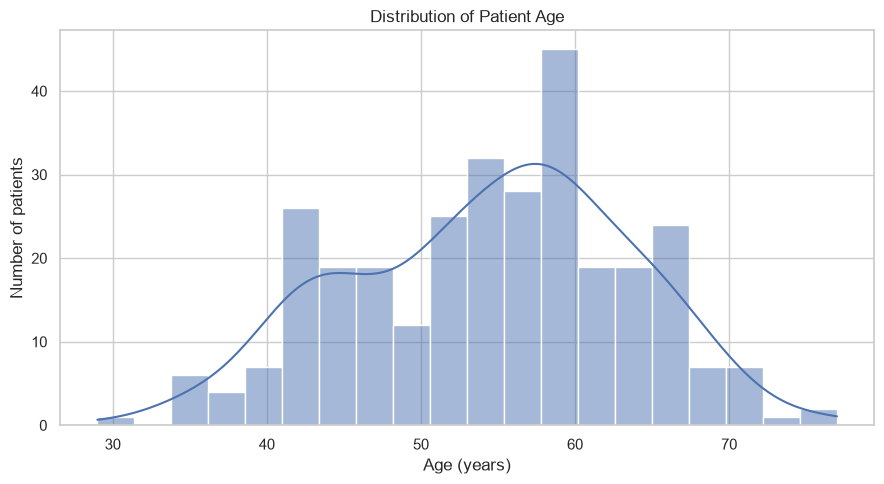

In [11]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="age", bins=20, kde=True)
plt.title("Distribution of Patient Age")
plt.xlabel("Age (years)")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.show()

### 7.2 Gender Distribution

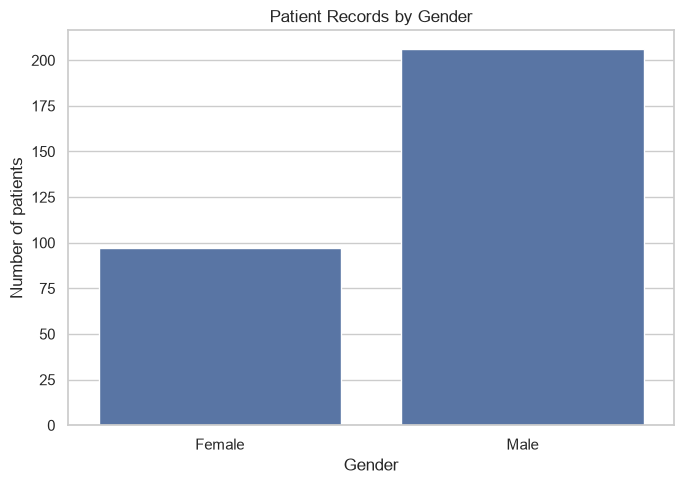

In [12]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sex")
plt.title("Patient Records by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of patients")
plt.xticks([0, 1], ["Female", "Male"])
plt.tight_layout()
plt.show()

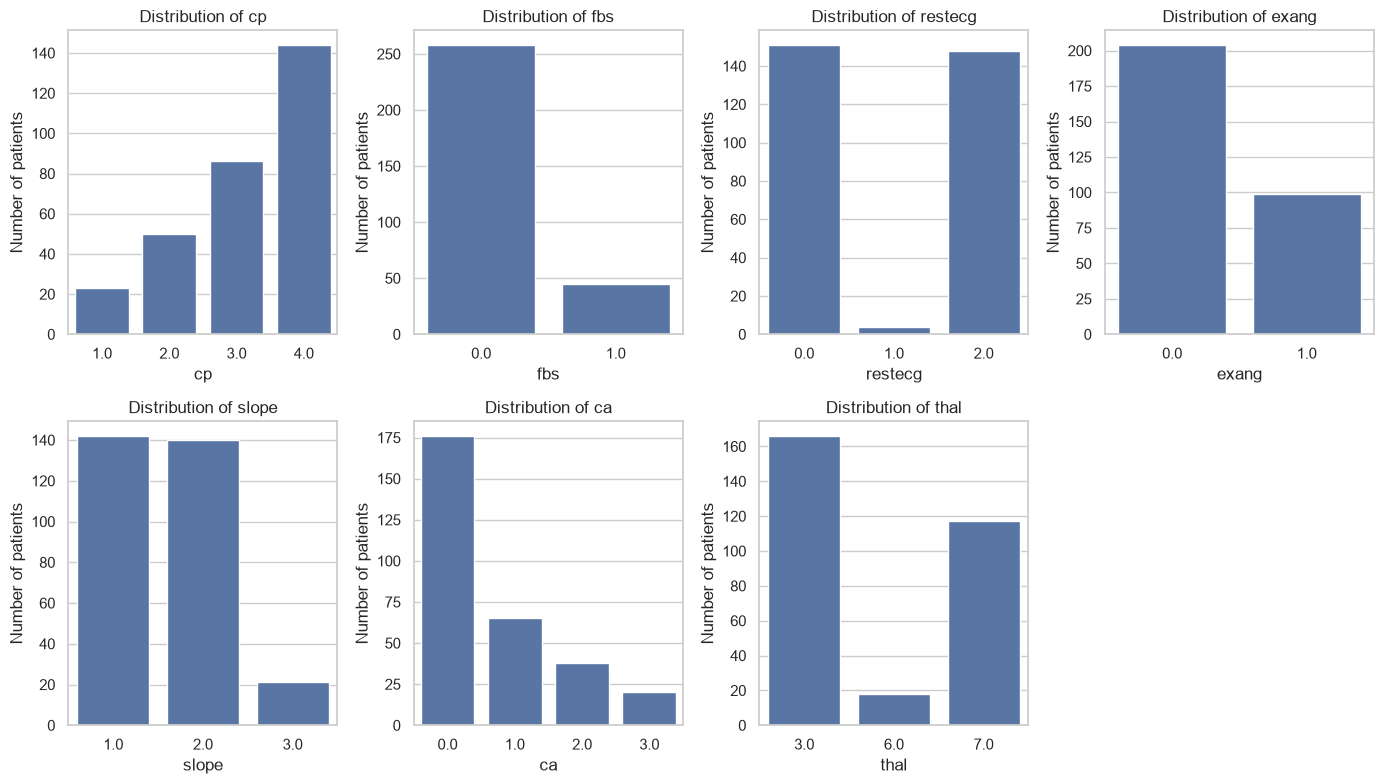

In [13]:
categorical_features = [
    "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of patients")

# Hide the unused sixth subplot.
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### 7.3 Numerical features distribution

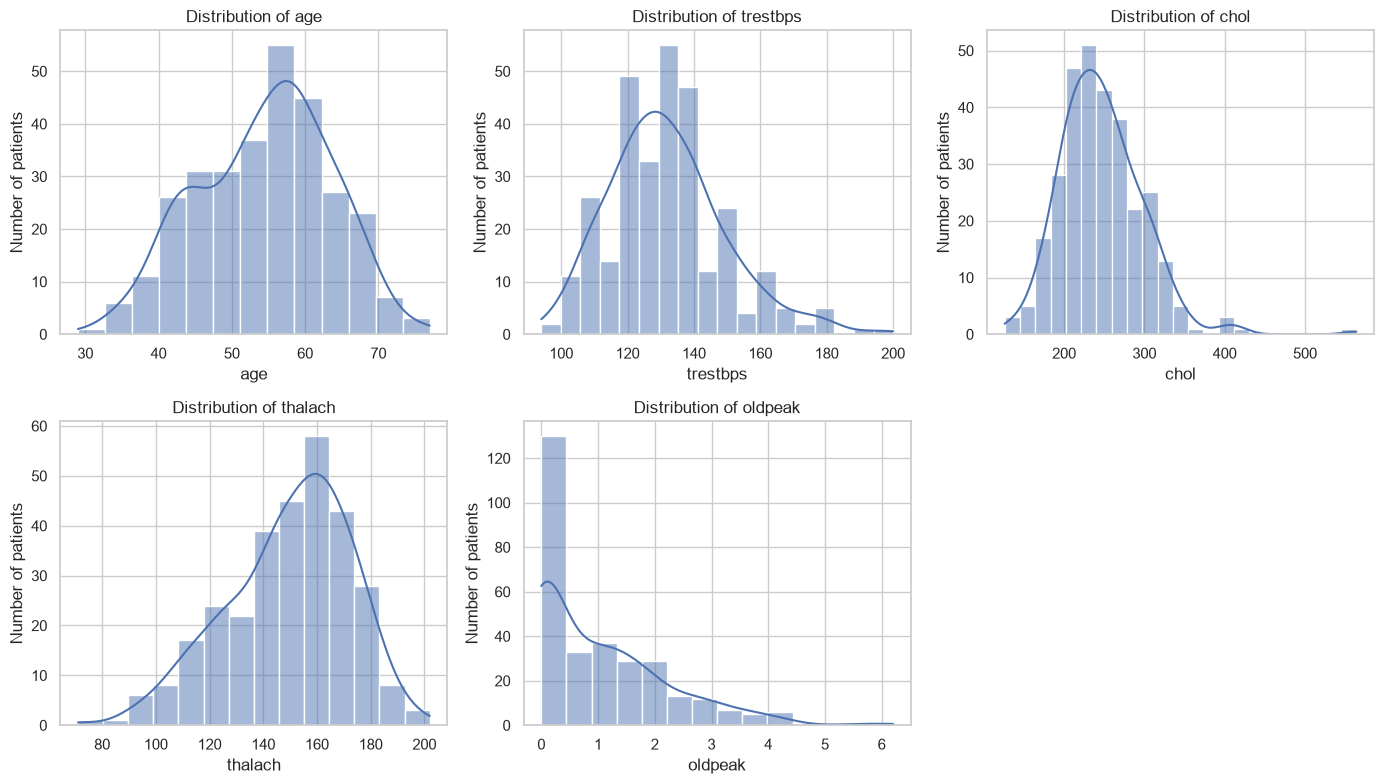

In [15]:
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of patients")

# Hide the unused sixth subplot.
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### 7.4 Target Distribution

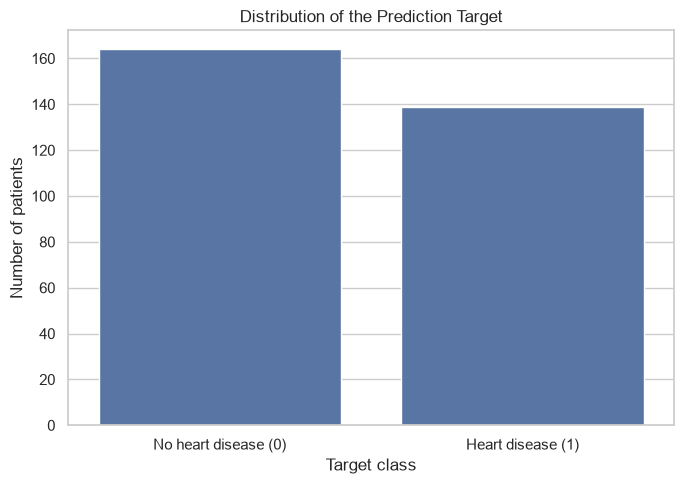

In [14]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="target")
ax.set_xticks([0, 1], ["No heart disease (0)", "Heart disease (1)"])
plt.title("Distribution of the Prediction Target")
plt.xlabel("Target class")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.show()

### 8. Relationship between numerical features

**8.1 Correlation analysis**
Correlation measures the strength and direction of a linear relationship between two numerical variables. Its values range from -1 to +1:
- Close to +1: strong positive linear relationship.
- Close to -1: strong negative linear relationship.
- Close to 0: little or no linear relationship.

The heatmap is a quick way to identify pairs that may be worth investigating. Correlation does not establish causation, and a low correlation does not mean a feature is unimportant to a machine-learning model.

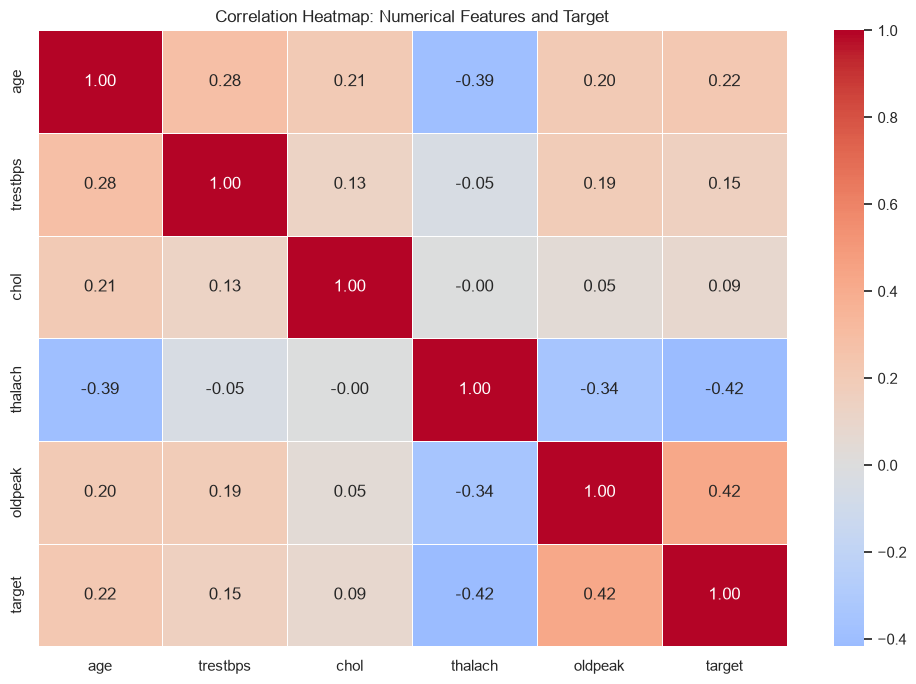

In [40]:
correlation_features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak", "target"
]

correlation_matrix = df[correlation_features].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Correlation Heatmap: Numerical Features and Target")
plt.tight_layout()
plt.show()

### 9. Outlier investigation
An outlier is an observation that is unusually far from the rest of the values in a feature. It may be a genuine rare observation, a measurement issue, or a data-entry error.

We use two complementary checks:
1. Boxplots to visually inspect the spread and potential extreme values.
2. The Interquartile Range (IQR) rule to flag values outside statistical boundaries.
Important: IQR flags are investigation prompts, not proof of bad data. We do not automatically remove these records.

## 9.1 Boxplot inspection
A boxplot displays the median, middle 50% of values (the box), and potential extreme observations (points beyond the whiskers).

The boxplot is useful for spotting features that have a wide spread or unusually distant observations.

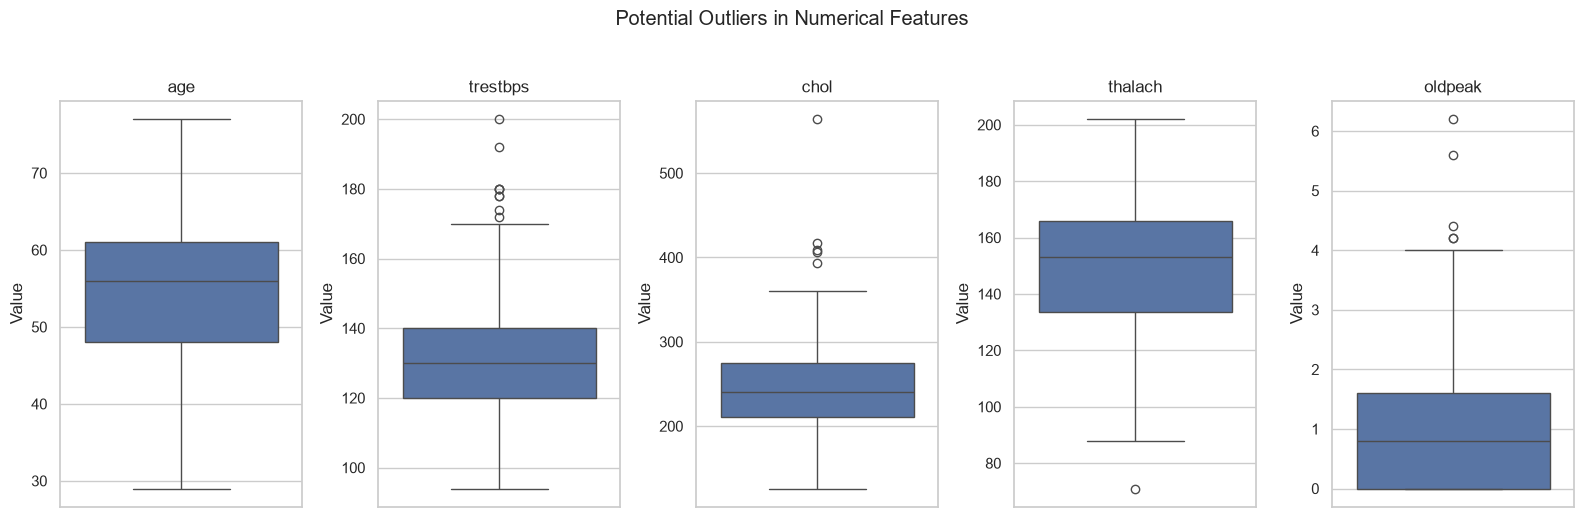

In [41]:
fig, axes = plt.subplots(1, len(numeric_features), figsize=(16, 5))

for ax, col in zip(axes, numeric_features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Value")

fig.suptitle("Potential Outliers in Numerical Features", y=1.03)
plt.tight_layout()
plt.show()

## 9.2 IQR-based outlier summary
For each numerical feature:
- Q1 is the 25th percentile.
- Q3 is the 75th percentile.
- IQR = Q3 - Q1.
- Lower boundary = Q1 - 1.5 × IQR.
- Upper boundary = Q3 + 1.5 × IQR.
Values outside these boundaries are flagged as potential outliers. The summary includes the number and percentage of flagged records for each feature.

In [42]:
outlier_summary = []

for col in numeric_features:
    series = df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    outlier_count = int(outlier_mask.sum())
    valid_count = int(df[col].notna().sum())

    outlier_summary.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outlier Count": outlier_count,
        "Potential Outlier Percentage": (
            outlier_count / valid_count * 100 if valid_count else np.nan
        )
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df.round(2))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outlier Count,Potential Outlier Percentage
0,age,48.0,61.0,13.0,28.50,80.50,0,0.00
1,trestbps,120.0,140.0,20.0,90.00,170.00,9,2.97
2,chol,211.0,275.0,64.0,115.00,371.00,5,1.65
3,thalach,133.5,166.0,32.5,84.75,214.75,1,0.33
4,oldpeak,0.0,1.6,1.6,-2.40,4.00,5,1.65


## 9.3 Review the flagged values
 We don't delete an observation only because it is outside an IQR boundary. For this project, we retain the observations unless there is evidence that a value is invalid or incorrectly recorded.

In [43]:
for col in numeric_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    flagged_values = df.loc[
        (df[col] < lower_bound) | (df[col] > upper_bound),
        col
    ].dropna().sort_values()

    print(f"\n{col}: {len(flagged_values)} potential outlier(s)")
    print(flagged_values.tolist())


age: 0 potential outlier(s)
[]

trestbps: 9 potential outlier(s)
[172.0, 174.0, 178.0, 178.0, 180.0, 180.0, 180.0, 192.0, 200.0]

chol: 5 potential outlier(s)
[394.0, 407.0, 409.0, 417.0, 564.0]

thalach: 1 potential outlier(s)
[71.0]

oldpeak: 5 potential outlier(s)
[4.2, 4.2, 4.4, 5.6, 6.2]


### 10. Prepare the modelling dataset
We now create the dataset that the model-experiment notebook will read.

Preparation decisions:
1. Keep the binary target column.
2. Remove num, because it is the original diagnosis field used to create the target. Keeping it as an input would cause target leakage.
3. Keep missing feature values at this stage. The modelling pipeline is responsible for imputing them using training data only.
4. Keep categorical codes as feature values; the modelling preprocessing pipeline should encode them as categorical variables.
The resulting file is a model-ready input table, not a fully imputed or scaled matrix. This naming distinction matters: imputation and scaling are learned during model training.

In [44]:
df_final = df.drop(columns=["num"]).copy()

target_column = "target"
feature_columns = [col for col in df_final.columns if col != target_column]

X = df_final[feature_columns].copy()
y = df_final[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape :", y.shape)
print("Final dataset shape :", df_final.shape)

display(df_final.head())

Feature matrix shape: (303, 13)
Target vector shape : (303,)
Final dataset shape : (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### 10.1 Confirm feature groups
We separate numerical measurements from categorical codes so that the modelling preprocessing can apply the appropriate transformations to each group.

Numerical features are scaled after missing-value imputation. Categorical features are imputed and one-hot encoded. The actual preprocessing is fitted within the model pipeline or on the training split only.

In [45]:
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

assert set(numeric_features + categorical_features) == set(feature_columns)

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


### 10.2 Final dataset validation
Before saving, we run a few checks:
- The target contains only 0 and 1.
- The target has no missing values.
- The original num field is not present.
- The expected feature columns are present.
- Missing feature values are reported rather than silently hidden.
If an assertion fails, stop and investigate before using the file for model training.

In [48]:
assert "num" not in df_final.columns, "Original diagnosis column must not be a model input."
assert target_column in df_final.columns, "Target column is missing."
assert df_final[target_column].notna().all(), "Target contains missing values."
assert set(df_final[target_column].unique()).issubset({0, 1}), "Target must be binary."
assert len(df_final) == len(df), "Record count changed unexpectedly."

final_missing_count = int(df_final.isna().sum().sum())

print("**FINAL DATASET VALIDATION**")
print("Target values:", sorted(df_final[target_column].unique().tolist()))
print("Target missing values:", int(df_final[target_column].isna().sum()))
print("Original 'num' column removed:", "num" not in df_final.columns)
print("Feature count:", len(feature_columns))
print("Record count:", len(df_final))
print("Remaining missing feature cells:", final_missing_count)

display(
    df_final.isna().sum()
    .rename("Missing values")
    .to_frame()
)

**FINAL DATASET VALIDATION**
Target values: [0, 1]
Target missing values: 0
Original 'num' column removed: True
Feature count: 13
Record count: 303
Remaining missing feature cells: 6


,Missing values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


### 10.3 Save the prepared dataset
We save the prepared table to data/processed/heart_disease_cleaned.csv.

This is the file loaded by 03_model_experiments.ipynb. It contains the original feature values and the binary target. Missing feature values are intentionally retained so that the modelling pipeline can learn imputation values from the training data only.

In [50]:
OUTPUT_DATA_PATH = PROCESSED_DIR / "heart_disease_model_input.csv"

df_final.to_csv(OUTPUT_DATA_PATH, index=False)

print("Prepared dataset saved successfully:")
print(OUTPUT_DATA_PATH)

Prepared dataset saved successfully:
C:\Users\ASUS\OneDrive\Documents\GitHub\heart-disease-risk-prediction\data\processed\heart_disease_cleaned.csv


### 11. Dataset audit summary

|**Audit area**|**What we checked**|**Why it matters**|
|:---|:---|:---|
|Structure|Number of rows and columns|Confirms the dataset loaded as expected|
|Missingness|Count and percentage of missing cells|Guides imputation decisions|
|Duplicates|Exact repeated rows|Identifies records worth reviewing|
|Target|Binary class distribution|Helps assess class balance|
|Feature types|Numerical measurements and categorical codes|Guides preprocessing|
|Outliers|IQR flags|Highlights values for review, not automatic deletion|
|Leakage|Removed original num field|Prevents the answer being included as an input|

In [51]:
audit_summary = pd.DataFrame([
    {"Audit Check": "Number of records", "Result": len(df_final), "Status": "Recorded"},
    {"Audit Check": "Number of model features", "Result": len(feature_columns), "Status": "Recorded"},
    {"Audit Check": "Exact duplicate rows in raw data", "Result": int(df.duplicated().sum()), "Status": "Review" if df.duplicated().any() else "No duplicates"},
    {"Audit Check": "Missing feature cells in prepared data", "Result": final_missing_count, "Status": "Handled in modelling pipeline" if final_missing_count else "No missing values"},
    {"Audit Check": "Missing target values", "Result": int(df_final[target_column].isna().sum()), "Status": "Pass"},
    {"Audit Check": "Target classes", "Result": sorted(df_final[target_column].unique().tolist()), "Status": "Pass"},
    {"Audit Check": "Original diagnosis field removed", "Result": "num" not in df_final.columns, "Status": "Pass"}
])

display(audit_summary)

,Audit Check,Result,Status
0,Number of records,303,Recorded
1,Number of model features,13,Recorded
2,Exact duplicate rows in raw data,0,No duplicates
3,Missing feature cells in prepared data,6,Handled in modelling pipeline
4,Missing target values,0,Pass
5,Target classes,"[0, 1]",Pass
6,Original diagnosis field removed,True,Pass


### 12. Conclusion and hand-off to model experiments
The dataset audit is complete. The prepared dataset has been saved for the next stage.
What this notebook establishes
- The raw dataset has been loaded and its columns documented.
- The original diagnosis field has been converted into a binary prediction target.
- Missing values, duplicate rows, data types, category frequencies, and potential outliers have been inspected.
- Numerical and categorical feature groups have been identified.
- The original num field has been excluded from the modelling input to avoid target leakage.
- The prepared dataset has been saved to data/processed/heart_disease_cleaned.csv.

Next notebook: 03_model_experiments.ipynb — train baseline classifiers, compare cross-validation performance, tune selected models, and evaluate the final candidates on the held-out test set.